# 05 · Optimización cuántica y comparación con la notebook 4

**QFire Cusco — ejecución del 24/10/2026.** La notebook 4 adjunta es **clásica (MILP/HiGHS)**. Esta ampliación implementa un método **híbrido con QAOA simulado** para la selección de rutas, conserva la asignación entera por recurso y compara ambos planes bajo la misma política.

Se trabaja sobre Anta, Calca, Paruro y Urubamba. Las demandas, flota e inventarios son simulados; las coordenadas y accesos conservan las limitaciones del adjunto. La ejecución utiliza CPU, sin QPU ni credenciales. Las notebooks 01–04 se conservan sin cambios.

Ejecute las celdas en orden desde la carpeta completa. Instale `requirements-quantum.txt`. Esta notebook recalcula una corrida predefinida; el benchmark de veinte corridas ya ejecutadas se carga de `data/results/phase5/`. Para regenerarlo: `python scripts/run_quantum.py`.

In [1]:
from pathlib import Path
import os, sys, json, time
os.environ.setdefault('OPENBLAS_NUM_THREADS','1')
os.environ.setdefault('OMP_NUM_THREADS','1')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

def locate_root():
    for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        if (p/'config/phase4.json').is_file() and (p/'src/qfire_cusco/optimization_quantum.py').is_file(): return p
    raise FileNotFoundError('Abra la carpeta completa del proyecto qfire-cusco.')
ROOT=locate_root(); RESULT=ROOT/'data/results/phase5'
sys.path.insert(0,str(ROOT/'src'))
from qfire_cusco.scenario import load_inputs, create_scenario, usable_stock
from qfire_cusco.optimization_classical import solve_classical, validate_plan
from qfire_cusco.optimization_quantum import (priority_allocation, prepare_qubo, basis_table,
    qaoa_sample, materialize_plan, statevector, qiskit_circuit)
def read(name):return json.loads((RESULT/name).read_text(encoding='utf-8'))
print('Backend: simulación ideal por vector de estado en CPU')

Backend: simulación ideal por vector de estado en CPU


## 1. Reproducción del escenario original

Se conservan las mismas prioridades, costos, stock, tiempos y geometrías. La fase 04 incorporaba separadores del sistema operativo en el hash; se normalizan las claves a `/` antes de crear el escenario, para recuperar en Windows el mismo identificador del adjunto. No se cambian archivos de entrada.

In [2]:
inputs=load_inputs(ROOT)
inputs.hashes={k.replace('\\','/'):v for k,v in inputs.hashes.items()}
profiles=json.loads((ROOT/'config/ejemplo_perfiles_fase4.json').read_text(encoding='utf-8'))
scenario=create_scenario(inputs,['ANTA','CALCA','PARURO','URUBAMBA'],profiles)
original=json.loads((ROOT/'data/results/phase4'/scenario.scenario_id/'metricas.json').read_text(encoding='utf-8'))
assert inputs.hashes=={k.replace('\\','/'):v for k,v in original['inputs_sha256'].items()}
print('Escenario:',scenario.scenario_id)
print('Versión de red:',inputs.manifest['red_version'])
display(scenario.profiles[['PROVINCIA','PUNTO_ID','BOMBEROS','PERSONAL_APOYO','PRIORIDAD_BASE','PLAZO_HORAS']])
display(pd.Series(usable_stock(inputs,scenario.config),name='STOCK_COER').to_frame())

Escenario: e183b86581fe680be96868c0efe425f5cc447334b2b886456effa1fa14696cbc
Versión de red: b9f79e7c3d61b5dc2165


,PROVINCIA,PUNTO_ID,BOMBEROS,PERSONAL_APOYO,PRIORIDAD_BASE,PLAZO_HORAS
0,ANTA,CAP_0803,80,10,75.8333,4.0
1,CALCA,CAP_0804,50,10,66.6667,5.0
2,PARURO,CAP_0810,45,10,68.1944,6.0
3,URUBAMBA,CAP_0813,25,15,66.8611,4.0


,STOCK_COER
AGUA,670
MASCARILLA,258
PALA,27
HACHA,12
PAQUETE_VETERINARIO,8
BOTIQUIN_BRIGADA,8


## 2. Asignación clásica antes del circuito

La contribución marginal de entregar una unidad del pedido $i,r$ es
$$b_{ir}=\lambda\,p_{ir}/(100\,d_{ir}).$$
Para cada recurso se asigna stock en orden decreciente de $b_{ir}$, con límites de demanda y autorización. Es un óptimo de la relajación por recurso, no una consulta al MILP. En esta instancia las cantidades coinciden posteriormente con el óptimo completo.

Antes de reducir, se exige que toda la carga asignada quepa en cualquier vehículo y que los tours elegidos sean factibles para todos. Cada destino se atenderá en una única visita; las cantidades quedan fijas. Estas restricciones pueden perder soluciones en otra instancia; el código rechaza capacidades incompatibles y tamaños fuera de su límite.

In [3]:
allocation=priority_allocation(scenario)
display(allocation[['PROVINCIA','RECURSO_ID','CANTIDAD_PENDIENTE','BENEFICIO_UNIDAD','CANTIDAD_ASIGNADA']])
catalog=inputs.catalog.set_index('RECURSO_ID')
weight=sum(r.CANTIDAD_ASIGNADA*catalog.loc[r.RECURSO_ID,'PESO_KG_UNIDAD'] for r in allocation.itertuples())
volume=sum(r.CANTIDAD_ASIGNADA*catalog.loc[r.RECURSO_ID,'VOLUMEN_M3_UNIDAD'] for r in allocation.itertuples())
print(f'Carga total: {weight:.2f} kg / {volume:.4f} m³')
display(inputs.fleet[['VEHICULO_ID','CAPACIDAD_KG','CAPACIDAD_M3']])

,PROVINCIA,RECURSO_ID,CANTIDAD_PENDIENTE,BENEFICIO_UNIDAD,CANTIDAD_ASIGNADA
0,ANTA,AGUA,360,2.106481,50
1,ANTA,MASCARILLA,108,5.617278,58
2,ANTA,PALA,24,22.118042,0
3,ANTA,HACHA,9,58.981444,1
4,ANTA,PAQUETE_VETERINARIO,1,758.333000,1
5,ANTA,BOTIQUIN_BRIGADA,4,189.583250,0
6,CALCA,AGUA,240,2.777779,240
7,CALCA,MASCARILLA,72,7.407417,72
8,CALCA,PALA,12,38.888917,12
9,CALCA,HACHA,5,93.333400,5


Carga total: 554.97 kg / 1.1867 m³


,VEHICULO_ID,CAPACIDAD_KG,CAPACIDAD_M3
0,VEH-01,650,3.0
1,VEH-02,900,4.5
2,VEH-03,1200,6.0


## 3. QUBO de selección de tours

Se conserva el tour factible de menor costo para cada subconjunto de hasta tres destinos: **14 tours** comunes a los vehículos. Los 14 bits $y_k$ eligen tours; $s_0,s_1$ representan holgura en el límite de tres vehículos.

$$E(y,s)=\sum_k c_k y_k+A\sum_i\left(\sum_k a_{ik}y_k-1\right)^2+A\left(\sum_k y_k+s_0+2s_1-3\right)^2.$$

$c_k=D_k+0.25T_k$. La asignación previa fija la penalización por faltantes. El QUBO minimiza transporte; para la comparación se reincorpora esa penalización y se evalúa el objetivo completo de la notebook 4.

Se usa $A=1+\sum_k c_k$. Los costos son no negativos y una violación entera cuesta al menos $A$: si existe una partición factible, el óptimo del QUBO es factible. La factibilidad se verifica de forma independiente. Convención matricial triangular: $E=\text{offset}+\sum_{i\leq j}Q_{ij}x_ix_j$, con orden little endian.

In [4]:
setup=time.perf_counter()
problem=prepare_qubo(scenario)
bits,energy,feasible=basis_table(problem)
setup_seconds=time.perf_counter()-setup
print(f'{problem.n} qubits; {len(problem.tours)} tours; A={problem.penalty:.6f}')
print(f'{len(energy):,} estados de base; {int(feasible.sum())} factibles')
display(pd.DataFrame([{'QUBIT':k,'DESTINOS':' → '.join(t['sequence']),'KM':t['km'],'MIN':t['minutes'],'COSTO':t['cost']} for k,t in enumerate(problem.tours)]))
assert problem.n==16 and feasible.sum()==13
print('Los dos últimos qubits codifican holgura con pesos',problem.slack_weights)

16 qubits; 14 tours; A=2788.587518
65,536 estados de base; 13 factibles


,QUBIT,DESTINOS,KM,MIN,COSTO
0,0,CAP_0803,53.266278,56.767220,67.458082
1,1,CAP_0804,102.468599,113.395177,130.817393
2,2,CAP_0810,117.595986,145.238578,153.905630
3,3,CAP_0813,104.379103,119.183491,134.174976
4,4,CAP_0803 → CAP_0804,128.971604,142.358417,164.561209
5,5,CAP_0803 → CAP_0810,167.755613,198.278062,217.325129
6,6,CAP_0803 → CAP_0813,111.136906,126.560349,142.776993
7,7,CAP_0810 → CAP_0804,206.045016,255.861791,270.010464
8,8,CAP_0813 → CAP_0804,124.404606,138.801452,159.104969
9,9,CAP_0813 → CAP_0810,218.868439,260.694333,284.042022


Los dos últimos qubits codifican holgura con pesos [1, 2]


## 4. Hamiltoniano y circuito QAOA

Con $x_i=(I-Z_i)/2$ se obtiene $H_C=C I+\sum_i h_i Z_i+\sum_{i<j}J_{ij}Z_iZ_j$, donde
$$h_i=-Q_{ii}/2-\tfrac14\sum_{j\ne i}Q_{\min(i,j),\max(i,j)},\qquad J_{ij}=Q_{ij}/4.$$

Se prepara $|+\rangle^{\otimes16}$ y se alterna $e^{-i\gamma_l H_C/A}$ con $e^{-i\beta_l\sum_i X_i}$. El circuito equivalente usa RZ, RZZ y RX. Una escala por la desviación del Hamiltoniano bajo la distribución uniforme acondiciona los parámetros de COBYLA; no utiliza el óptimo.

**Protocolo fijado:** p=3, semilla 42, máximo de 250 evaluaciones y 4.096 shots finales. Se minimiza la esperanza exacta del vector de estado; los shots se usan sólo al final. Este entrenamiento ideal difiere de estimar la energía con un número finito de mediciones en una QPU.

,CORRIDA_PRINCIPAL
depth,3
seed,42
shots,4096
evaluations,250
optimizer_success,False
optimizer_message,Return from COBYLA because the objective funct...
gamma_parameter_spread,43.232325
expectation_scaled,4.494003
feasible_probability,0.016494
optimal_probability,0.001379


Estado medido elegido: 18436
COBYLA: Return from COBYLA because the objective function has been evaluated MAXFUN times.


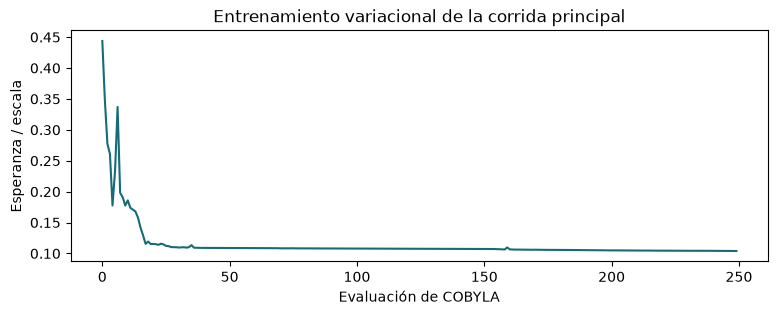

In [5]:
result=qaoa_sample(problem,energy,feasible,depth=3,seed=42,shots=4096,maxiter=250)
display(pd.Series({k:v for k,v in result.items() if k not in ['theta','counts','history']},name='CORRIDA_PRINCIPAL').to_frame())
print('Estado medido elegido:',result['chosen_state'])
print('COBYLA:',result['optimizer_message'])
fig,ax=plt.subplots(figsize=(9,3))
ax.plot(result['history'],color='#156b78')
ax.set(xlabel='Evaluación de COBYLA',ylabel='Esperanza / escala',title='Entrenamiento variacional de la corrida principal')
plt.show()

## 5. Decodificación y comprobación física

Se elige el estado factible de menor costo entre las muestras observadas. Una corrida sin muestras factibles se informa como fallo; no se repara con el MILP. A continuación se asignan los tours a vehículos compatibles y se reconstruyen las cantidades, tiempos, cargas y geometrías usando las funciones del proyecto.

In [6]:
quantum=materialize_plan(scenario,problem,bits,result['chosen_state'])
assert validate_plan(scenario,quantum)
classical=solve_classical(scenario)
assert validate_plan(scenario,classical)
comparison=pd.DataFrame([
    {'METRICA':key,'NOTEBOOK04_ADJUNTO':original[key],'MILP_RECALCULADO':classical.metrics[key],
     'HIBRIDO_QAOA':quantum.metrics[key]}
    for key in ['objetivo','costo_transporte','penalizacion_faltantes','distancia_km','duracion_vial_min','vehiculos_utilizados']])
display(comparison)
full_gap=100*(quantum.metrics['objetivo']-classical.metrics['objetivo'])/classical.metrics['objetivo']
print(f'Brecha completa de esta corrida: {full_gap:.6f}%')
print('Estado MILP:',classical.metrics['estado_solver'],'; MIP gap:',classical.metrics['mip_gap'])
display(pd.DataFrame(quantum.routes))
display(quantum.stops)

,METRICA,NOTEBOOK04_ADJUNTO,MILP_RECALCULADO,HIBRIDO_QAOA
0,objetivo,3821.502833,3821.502833,3821.502833
1,costo_transporte,321.612616,321.612616,321.612616
2,penalizacion_faltantes,3499.890217,3499.890217,3499.890217
3,distancia_km,248.758394,248.758394,248.758394
4,duracion_vial_min,291.416888,291.416888,291.416888
5,vehiculos_utilizados,2.000000,2.000000,2.000000


Brecha completa de esta corrida: 0.000000%
Estado MILP: OPTIMO_DEL_MODELO_RESTRINGIDO ; MIP gap: 0.0


,VEHICULO_ID,SECUENCIA,SALIDA_EN,RETORNO_EN,DISTANCIA_KM,DURACION_VIAL_MIN,CARGA_INICIAL_KG,VOLUMEN_INICIAL_M3,CAPACIDAD_KG,CAPACIDAD_M3
0,VEH-01,"[COER_CUSCO, CAP_0810, COER_CUSCO]",2026-10-24T08:00:00-05:00,2026-10-24T10:40:14.314667431-05:00,117.595986,145.238578,189.40,0.4260,650.0,3.0
1,VEH-02,"[COER_CUSCO, CAP_0803, CAP_0813, CAP_0804, COE...",2026-10-24T08:00:00-05:00,2026-10-24T11:11:10.698617456-05:00,131.162409,146.178310,365.57,0.7607,900.0,4.5


,VEHICULO_ID,ORDEN,PUNTO_ID,PROVINCIA,LLEGADA_EN,ENTREGA_EN,CARGA_ANTES_KG,CARGA_DESPUES_KG,VOLUMEN_ANTES_M3,VOLUMEN_DESPUES_M3
0,VEH-01,1,CAP_0810,PARURO,2026-10-24T09:12:39.969429377-05:00,2026-10-24T09:27:39.969429377-05:00,189.40,0.000000e+00,0.4260,0.0000
1,VEH-02,1,CAP_0803,ANTA,2026-10-24T08:28:20.450866843-05:00,2026-10-24T08:43:20.450866843-05:00,365.57,3.274000e+02,0.7607,0.6900
2,VEH-02,2,CAP_0813,URUBAMBA,2026-10-24T09:21:48.735586055-05:00,2026-10-24T09:36:48.735586055-05:00,327.40,2.050800e+02,0.6900,0.4588
3,VEH-02,3,CAP_0804,CALCA,2026-10-24T09:59:41.657451437-05:00,2026-10-24T10:14:41.657451437-05:00,205.08,2.842171e-14,0.4588,0.0000


## 6. Entregas por recurso

Se comparan cantidades y coberturas usando la unidad de cada recurso. El faltante de stock persiste; QAOA no crea existencias adicionales. Los planes y geometrías exportados del benchmark se conservan en `data/results/phase5/`.

,RECURSO,DEMANDA,MILP,QAOA,FALTANTE,COBERTURA_PCT
0,AGUA,980,670,670,310,68.367347
1,BOTIQUIN_BRIGADA,12,8,8,4,66.666667
2,HACHA,20,12,12,8,60.000000
3,MASCARILLA,308,258,258,50,83.766234
4,PALA,51,27,27,24,52.941176
5,PAQUETE_VETERINARIO,17,8,8,9,47.058824


,PROVINCIA,RECURSO_ID,CANTIDAD_PENDIENTE,CANTIDAD_ASIGNADA,CANTIDAD_FALTANTE,COBERTURA
0,ANTA,AGUA,360,50,310,0.138889
1,ANTA,MASCARILLA,108,58,50,0.537037
2,ANTA,PALA,24,0,24,0.000000
3,ANTA,HACHA,9,1,8,0.111111
4,ANTA,PAQUETE_VETERINARIO,1,1,0,1.000000
5,ANTA,BOTIQUIN_BRIGADA,4,0,4,0.000000
6,CALCA,AGUA,240,240,0,1.000000
7,CALCA,MASCARILLA,72,72,0,1.000000
8,CALCA,PALA,12,12,0,1.000000
9,CALCA,HACHA,5,5,0,1.000000


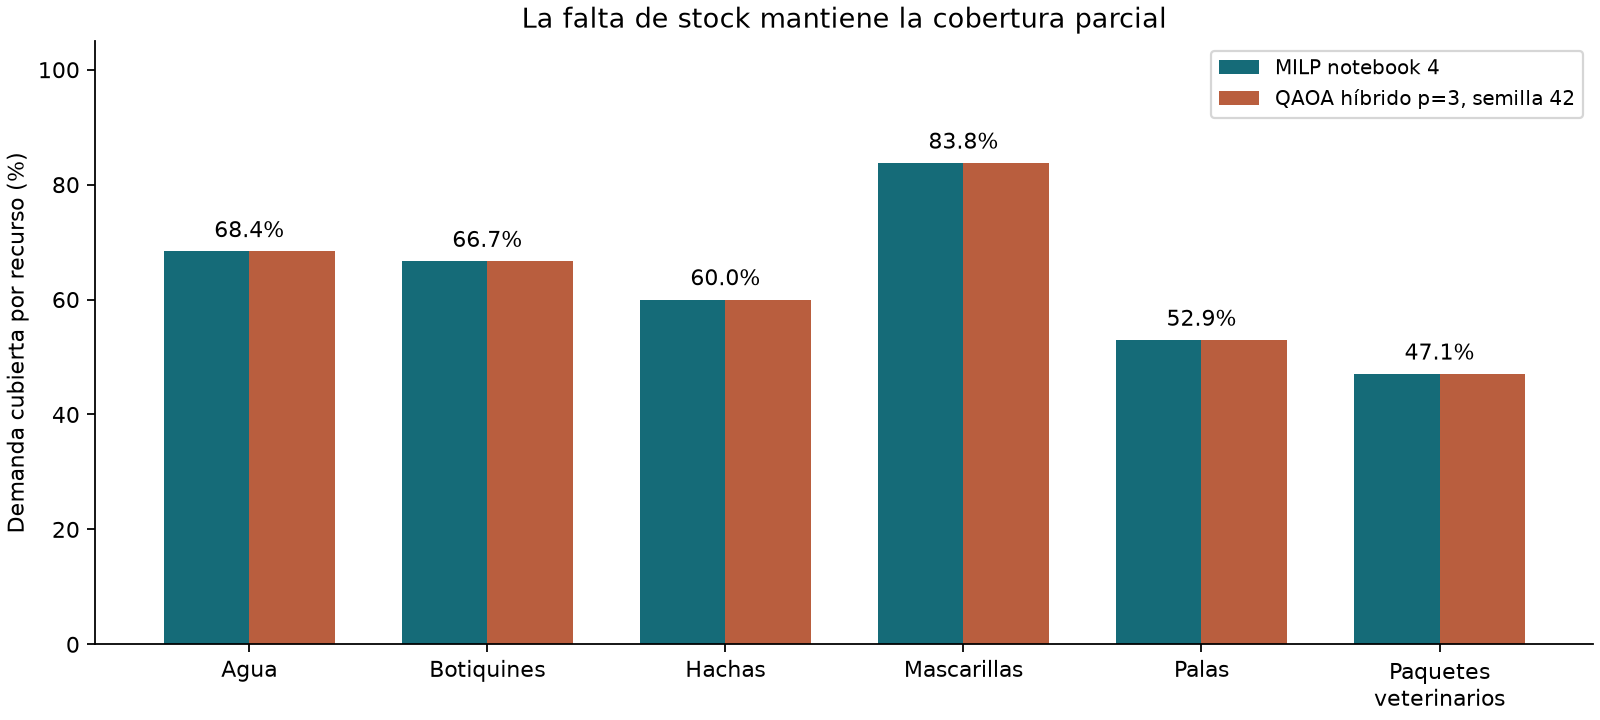

In [7]:
by_resource=[]
for resource,values in classical.metrics['recursos'].items():
    other=quantum.metrics['recursos'][resource]
    by_resource.append({'RECURSO':resource,'DEMANDA':values['solicitado'],'MILP':values['asignado'],
        'QAOA':other['asignado'],'FALTANTE':other['faltante'],'COBERTURA_PCT':100*other['cobertura']})
display(pd.DataFrame(by_resource))
display(quantum.unmet[['PROVINCIA','RECURSO_ID','CANTIDAD_PENDIENTE','CANTIDAD_ASIGNADA','CANTIDAD_FALTANTE','COBERTURA']])
display(Image(filename=str(ROOT/'outputs/figures/05_cobertura_comparada.png')))

## 7. Benchmark guardado: diez semillas y dos profundidades

Se muestran **las veinte corridas** del script `run_quantum.py`: semillas 42–51, p=1 y p=3, 4.096 shots y hasta 250 evaluaciones. El óptimo exacto de los 65.536 estados se utiliza sólo como referencia posterior. La inicialización, entrenamiento y elección de muestras no reciben la solución exacta ni la solución MILP.

La evaluación QAOA distingue la probabilidad ideal de un estado, el resultado finito de muestreo y la convergencia de COBYLA. Un plan válido puede provenir de un entrenamiento que agotó su presupuesto.

,depth,seed,feasible_shots,optimal_sampled,objective_full,full_gap_pct,total_pipeline_seconds,optimizer_success
0,1,42,54,True,3821.502833,0.000000,1.460325,True
1,1,43,73,True,3821.502833,0.000000,1.344987,True
2,1,44,48,True,3821.502833,0.000000,1.062996,True
3,1,45,70,True,3821.502833,0.000000,1.744766,True
4,1,46,59,True,3821.502833,0.000000,1.494095,True
5,1,47,69,True,3821.502833,0.000000,1.432211,True
6,1,48,71,True,3821.502833,0.000000,1.590657,True
7,1,49,63,True,3821.502833,0.000000,0.910203,True
8,1,50,51,True,3821.502833,0.000000,1.275138,True
9,1,51,73,True,3821.502833,0.000000,0.827538,True


,CORRIDAS,OPTIMOS,BRECHA_MEDIA_PCT,BRECHA_MAX_PCT,PROB_FACTIBLE_MEDIA,MEDIANA_SEGUNDOS,COBYLA_CONVERGIO
depth,,,,,,,
1,10,10,0.000000,0.000000,0.015934,1.388599,10
3,10,9,0.116831,1.168314,0.015896,5.840444,0


,seed,shots,feasible_shots,best_transport,optimal_sampled
0,42,4096,0,NaN,False
1,43,4096,1,321.612616,True
2,44,4096,1,452.641815,False
3,45,4096,1,438.432908,False
4,46,4096,0,NaN,False
5,47,4096,0,NaN,False
6,48,4096,1,427.500017,False
7,49,4096,0,NaN,False
8,50,4096,2,380.468682,False
9,51,4096,2,423.461433,False


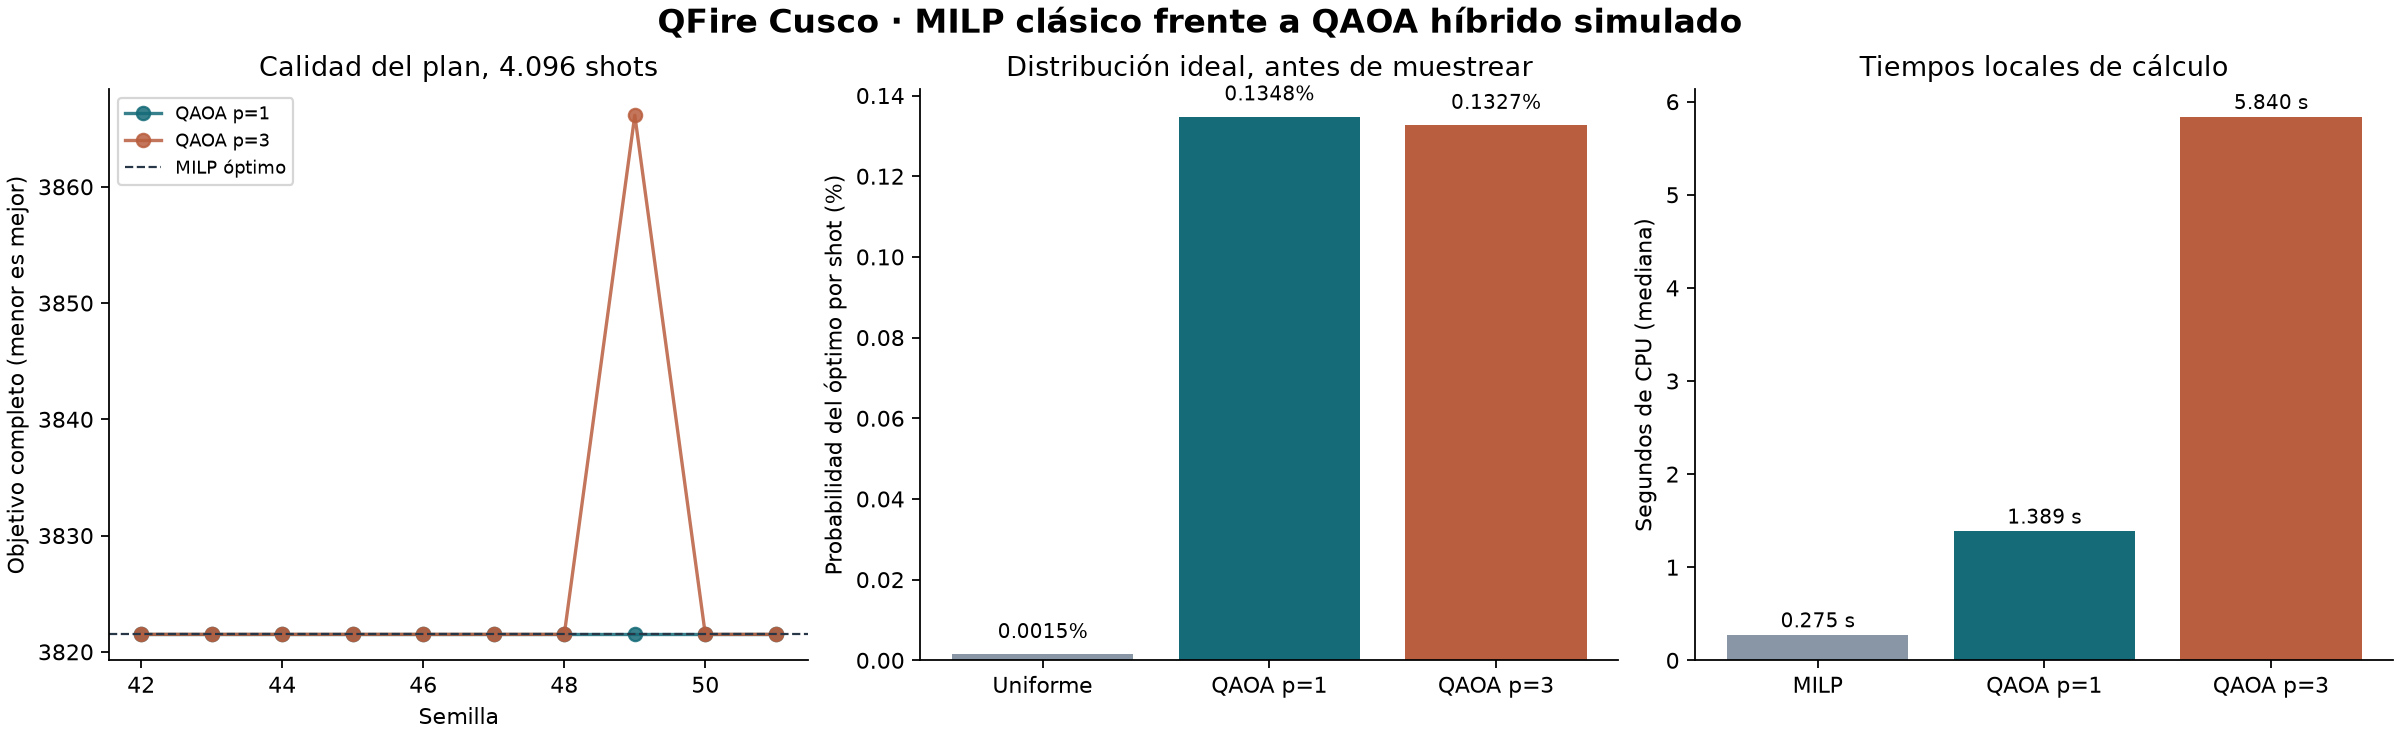

Tiempo MILP local mediano: 0.27452010003617033 s


In [8]:
benchmark=pd.read_csv(RESULT/'benchmark_qaoa.csv')
milp_times=pd.read_csv(RESULT/'benchmark_milp.csv')
control=pd.read_csv(RESULT/'control_uniforme.csv')
display(benchmark[['depth','seed','feasible_shots','optimal_sampled','objective_full','full_gap_pct','total_pipeline_seconds','optimizer_success']])
display(benchmark.groupby('depth').agg(CORRIDAS=('seed','size'),OPTIMOS=('optimal_sampled','sum'),
    BRECHA_MEDIA_PCT=('full_gap_pct','mean'),BRECHA_MAX_PCT=('full_gap_pct','max'),
    PROB_FACTIBLE_MEDIA=('feasible_probability','mean'),MEDIANA_SEGUNDOS=('total_pipeline_seconds','median'),
    COBYLA_CONVERGIO=('optimizer_success','sum')))
display(control)
display(Image(filename=str(ROOT/'outputs/figures/05_benchmark_cuantico.png')))
print('Tiempo MILP local mediano:',milp_times.wall_seconds.median(),'s')

**Alcance de los tiempos.** El tiempo MILP incluye resolución y materialización. El indicador QAOA incluye preparación QUBO, entrenamiento y muestreo; excluye decodificación, verificación Qiskit, referencia exacta y E/S. Ambos excluyen carga de entradas y elaboración del informe. Son mediciones locales con variabilidad, sin aislamiento de CPU; no son tiempos de QPU ni demuestran aceleración cuántica. El control uniforme tiene los mismos shots finales, pero no el costo de entrenamiento: informa concentración de probabilidad, sin equivalencia de recursos totales.

## 8. Verificación independiente del circuito

Se ejecuta el circuito de 16 qubits en Qiskit y se comprueba su fidelidad con el simulador NumPy, ignorando la fase global. El archivo `circuito_qaoa.qasm` contiene el circuito exportable; requiere compilación adicional para un dispositivo concreto.

In [9]:
from qiskit.quantum_info import Statevector
circuit=qiskit_circuit(problem,result['theta'])
actual=Statevector.from_instruction(circuit).data
expected=statevector(result['theta'],energy/problem.penalty)
fidelity=float(abs(np.vdot(actual,expected))**2)
assert fidelity>1-1e-9
print('Fidelidad NumPy / Qiskit:',fidelity)
print('Puertas lógicas:',dict(circuit.count_ops()),'; profundidad lógica:',circuit.depth())
display(pd.Series(read('validacion.json'),name='VERIFICACION_BENCHMARK').to_frame())

Fidelidad NumPy / Qiskit: 1.0000000000000049
Puertas lógicas: {'rzz': 360, 'rz': 48, 'rx': 48, 'h': 16} ; profundidad lógica: 68


,VERIFICACION_BENCHMARK
inputs_iguales_al_adjunto,True
escenario_id_igual_al_adjunto,True
objetivo_milp_reproducido,True
qubo_error_maximo,0.0
qubo_optimo_factible,True
qiskit_fidelidad,1.0
plan_qaoa_valido,True
plan_milp_valido,True
asignacion_previa_igual_a_milp,True
notebook04_sha256,082127fa43f578b8f5416b343600de08de78249626f218...


## 9. Conclusión comparativa

La corrida principal reproduce el objetivo y los kilómetros de la notebook 4. La referencia clásica certifica el óptimo del modelo restringido; la igualdad se observa y verifica para esta instancia. La reducción no garantiza equivalencia del problema general para otros inventarios, flotas o escenarios.

En el benchmark, p=1 alcanzó el óptimo en 10/10 corridas y p=3 en 9/10. La semilla 49 de p=3 tuvo una brecha total de 1,1683 %. Las diez corridas p=3 agotaron 250 evaluaciones: aumentar profundidad no mejoró el desempeño con este presupuesto. El híbrido simulado requirió más tiempo de CPU que el MILP local y no mejoró su objetivo. Estos datos no establecen ventaja cuántica.

La cobertura parcial procede de la escasez de recursos y coincide entre ambos planes principales. Se verificaron stock, demandas enteras, autorizaciones, capacidades, horarios, retorno y geometrías con el validador original.

**Límites:** simulación ideal sin ruido; entrenamiento con esperanza exacta; crecimiento exponencial del vector de estado; cantidades previamente fijadas; tours comunes a la flota; entregas sin división entre vehículos. Los datos y sitios operativos mantienen su condición simulada y provisional.

**Referencias del método:** [Farhi, Goldstone y Gutmann, 2014](https://arxiv.org/abs/1411.4028), [tutorial QAOA de IBM Quantum](https://quantum.cloud.ibm.com/docs/en/tutorials/quantum-approximate-optimization-algorithm). Los resultados numéricos proceden exclusivamente del adjunto y de las ejecuciones incluidas.